## Метод Ньютона

функции из лекции

In [44]:
import math
def newton(f, df, x0, eps=1e-12, max_iter=100):
    """
    Метод Ньютона (касательных).
    Возвращает: (корень, журнал, статус)
    """
    journal = []
    x = x0
    for k in range(1, max_iter + 1):
        fx = f(x)
        dfx = df(x)
        if dfx == 0:
            return x, journal, "zero_derivative"
        x_new = x - fx / dfx
        journal.append({"iter": k, "x": x, "f(x)": fx, "f'(x)": dfx, "x_new": x_new, "step": abs(x_new - x)})
        if abs(x_new - x) < eps or abs(fx) < eps:
            return x_new, journal, "ok"
        x = x_new
    return x, journal, "max_iter"


def secant(f, x0, x1, eps=1e-12, max_iter=100):
    """
    Метод секущих.
    Возвращает: (корень, журнал, статус)
    """
    journal = []
    x_prev, x_curr = x0, x1
    f_prev, f_curr = f(x_prev), f(x_curr)

    for k in range(1, max_iter + 1):
        if f_curr - f_prev == 0:
            return x_curr, journal, "zero_denominator"
        x_new = x_curr - f_curr * (x_curr - x_prev) / (f_curr - f_prev)
        journal.append({"iter": k,"x_prev": x_prev,"x_curr": x_curr,"f_curr": f_curr,"x_new": x_new,"step": abs(x_new - x_curr)})
        if abs(x_new - x_curr) < eps or abs(f_curr) < eps:
            return x_new, journal, "ok"
        x_prev, f_prev = x_curr, f_curr
        x_curr = x_new
        f_curr = f(x_curr)
    return x_curr, journal, "max_iter"


def bisection(f, a, b, eps=1e-9, max_iter=200):
    """
    Метод половинного деления с журналом итераций.

    Возвращает: (корень, журнал, статус)
    статус = 'ok' — достигнута точность по длине интервала
    статус = 'f_zero' — f(c) == 0 (точное попадание)
    статус = 'max_iter' — исчерпан лимит итераций
    """

    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError(f"Нет смены знака на [{a}, {b}]: f(a)={fa}, f(b)={fb}")

    journal = [] # список словарей — каждая запись = одна итерация

    for k in range(1, max_iter + 1):
        c = (a + b) / 2
        fc = f(c)
        length = b - a
        # записываем всё, что нужно для аудита
        journal.append({"iter": k, "a": a, "b": b, "c": c, "f(c)": fc, "length": length,})

        # условия остановки
        if fc == 0:
            return c, journal, "f_zero"
        if length < eps:
            return c, journal, "ok"

        # обновляем интервал
        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc

    return c, journal, "max_iter"

def print_journal_newton(journal, title=""):
    if title:
        print(f"\n=== {title} ===")
    print(f"{'k':>3} | {'x':>14} | {'f(x)':>14} | {'f\'(x)':>14} | {'шаг':>10}")
    print("-" * 70)
    for row in journal:
        print(f"{row['iter']:>3} | {row['x']:>14.10f} | {row['f(x)']:>14.3e} | "
            f"{row['f\'(x)']:>14.3e} | {row['step']:>10.2e}")


def print_journal_secant(journal, title=""):
    if title:
        print(f"\n=== {title} ===")
    print(f"{'k':>3} | {'x_prev':>14} | {'x_curr':>14} | {'f_curr':>14} | {'шаг':>10}")
    print("-" * 70)
    for row in journal:
        print(f"{row['iter']:>3} | {row['x_prev']:>14.10f} | {row['x_curr']:>14.1} | {row['f_curr']:>14.1} | {row['step']:>10.2e}")


def print_journal_bisect(journal, title=""):
    if title:
        print(f"\n=== {title} ===")
        print(f"{'k':>3} | {'a':>12} | {'b':>12} | {'c':>12} | "
        f"{'f(c)':>14} | {'b-a':>10}")
    print("-" * 80)
    for row in journal:
        print(f"{row['iter']:>3} | {row['a']:>12.6f} | {row['b']:>12.6f} | "
        f"{row['c']:>12.6f} | {row['f(c)']:>14.3e} | "
        f"{row['length']:>10.2e}")



## Задача 1. Сравнить методы на функции с плохим стартом
Условие. Дана функция f(x) = x³ − 2x + 2. У неё один действительный корень (около −1.769).
1. Постройте график на [−3, 3]. Убедитесь, что корень один.


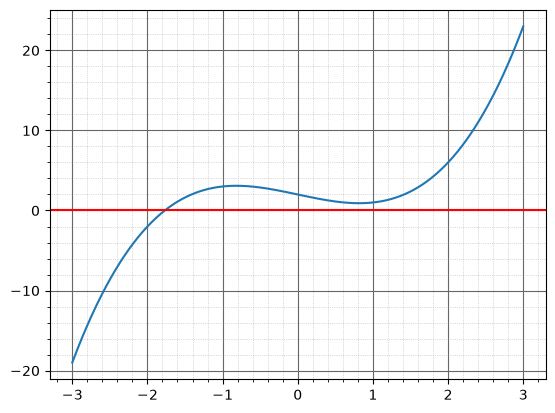

In [45]:
import numpy as np
import matplotlib.pyplot as plt

a, b = -3.0, 3.0
x = np.arange(a, b, 0.001)
y = x**3 - 2*x + 2

ax = plt.subplot()
ax.minorticks_on() # мелкие деления что бы лучше видеть границы где нахождится корень

ax.plot(x, y)

# 2. Настраиваем сетку для основных (больших) делений
ax.grid(which='major', color='#666666', linestyle='-', linewidth=0.8)

# 3. Настраиваем сетку для вспомогательных (внутренних) делений
ax.grid(which='minor', color='#999999', linestyle=':', linewidth=0.5, alpha=0.7)

# Красная горизонтальная линия на уровне y = 0
ax.axhline(0, color='red', linewidth=1.5)

plt.show()


**График функции.** На отрезке [-3;3]

График пересекает ось Ox один раз. 

Действительный корень находится приблизительно в точке x примерно -1.8


2. Запустите метод Ньютона с x0 = 0. Что происходит? Почему метод не сходится?
(Подсказка: постройте журнал и посмотрите на f′(xk).)


In [46]:
f = lambda x: x**3 - 2*x + 2 # функция
fp = lambda x: 3*x**2 - 2 # производная

x0 = 0
xx, j1, s1 = newton(f, fp, x0)

print_journal_newton(j1, f"f(x) = x³ - 2x + 2 ; x0 = {x0}")
print(f"корень: {xx:.12f}, f({xx}) = {f(xx):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")



=== f(x) = x³ - 2x + 2 ; x0 = 0 ===
  k |              x |           f(x) |          f'(x) |        шаг
----------------------------------------------------------------------
  1 |   0.0000000000 |      2.000e+00 |     -2.000e+00 |   1.00e+00
  2 |   1.0000000000 |      1.000e+00 |      1.000e+00 |   1.00e+00
  3 |   0.0000000000 |      2.000e+00 |     -2.000e+00 |   1.00e+00
  4 |   1.0000000000 |      1.000e+00 |      1.000e+00 |   1.00e+00
  5 |   0.0000000000 |      2.000e+00 |     -2.000e+00 |   1.00e+00
  6 |   1.0000000000 |      1.000e+00 |      1.000e+00 |   1.00e+00
  7 |   0.0000000000 |      2.000e+00 |     -2.000e+00 |   1.00e+00
  8 |   1.0000000000 |      1.000e+00 |      1.000e+00 |   1.00e+00
  9 |   0.0000000000 |      2.000e+00 |     -2.000e+00 |   1.00e+00
 10 |   1.0000000000 |      1.000e+00 |      1.000e+00 |   1.00e+00
 11 |   0.0000000000 |      2.000e+00 |     -2.000e+00 |   1.00e+00
 12 |   1.0000000000 |      1.000e+00 |      1.000e+00 |   1.00e+00
 13 |   

**Метод не сходится:** птому что приближения чередуются между двумя значениями x  0 и 1

3. Запустите метод Ньютона с x0 = −2. Сколько итераций?


In [47]:
f = lambda x: x**3 - 2*x + 2 # функция
fp = lambda x: 3*x**2 - 2 # производная

x0 = -2
xx, j1, s1 = newton(f, fp, x0)

print_journal_newton(j1, f"f(x) = x³ - 2x + 2 ; x0 = {x0}")
print(f"корень: {xx:.12f}, f({xx}) = {f(xx):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")



=== f(x) = x³ - 2x + 2 ; x0 = -2 ===
  k |              x |           f(x) |          f'(x) |        шаг
----------------------------------------------------------------------
  1 |  -2.0000000000 |     -2.000e+00 |      1.000e+01 |   2.00e-01
  2 |  -1.8000000000 |     -2.320e-01 |      7.720e+00 |   3.01e-02
  3 |  -1.7699481865 |     -4.850e-03 |      7.398e+00 |   6.56e-04
  4 |  -1.7692926629 |     -2.281e-06 |      7.391e+00 |   3.09e-07
  5 |  -1.7692923542 |     -5.054e-13 |      7.391e+00 |   6.84e-14
корень: -1.769292354239, f(-1.7692923542386314) = 0.000e+00, статус: ok
итераций: 5


Метод сошелся за 5 итераций.


4. Запустите метод секущих с x0 = −2, x1 = −1. Сколько итераций?


In [48]:
x0 = -2.0
x1 = -1.0
xx, j1, s1 = secant(f, x0, x1)
print_journal_secant(j1, f"f(x) = x³ - 2x + 2 ; [{x0};{x1}]")
print(f"корень: {xx:.12f}, f({xx}) = {f(xx):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")



=== f(x) = x³ - 2x + 2 ; [-2.0;-1.0] ===
  k |         x_prev |         x_curr |         f_curr |        шаг
----------------------------------------------------------------------
  1 |  -2.0000000000 |         -1e+00 |          3e+00 |   6.00e-01
  2 |  -1.0000000000 |         -2e+00 |          1e+00 |   3.49e-01
  3 |  -1.6000000000 |         -2e+00 |         -2e+00 |   2.02e-01
  4 |  -1.9493670886 |         -2e+00 |            0.2 |   1.91e-02
  5 |  -1.7476129346 |         -2e+00 |           0.02 |   2.62e-03
  6 |  -1.7667091237 |         -2e+00 |        -0.0003 |   4.08e-05
  7 |  -1.7693330951 |         -2e+00 |          6e-07 |   7.57e-08
  8 |  -1.7692922786 |         -2e+00 |          2e-11 |   2.21e-12
  9 |  -1.7692923542 |         -2e+00 |          0e+00 |   0.00e+00
корень: -1.769292354239, f(-1.7692923542386314) = 0.000e+00, статус: ok
итераций: 9


Метод сошелся за 9 итераций

5. Запустите бисекцию на [−2, −1]. Сколько итераций?


In [49]:
x0 = -2.0
x1 = -1.0
xx, j1, s1 = bisection(f, x0, x1)
print_journal_bisect(j1, f"f(x) = x³ - 2x + 2 ; [{x0};{x1}]")
print(f"корень: {xx:.12f}, f({xx}) = {f(xx):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")



=== f(x) = x³ - 2x + 2 ; [-2.0;-1.0] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |    -2.000000 |    -1.000000 |    -1.500000 |      1.625e+00 |   1.00e+00
  2 |    -2.000000 |    -1.500000 |    -1.750000 |      1.406e-01 |   5.00e-01
  3 |    -2.000000 |    -1.750000 |    -1.875000 |     -8.418e-01 |   2.50e-01
  4 |    -1.875000 |    -1.750000 |    -1.812500 |     -3.293e-01 |   1.25e-01
  5 |    -1.812500 |    -1.750000 |    -1.781250 |     -8.914e-02 |   6.25e-02
  6 |    -1.781250 |    -1.750000 |    -1.765625 |      2.703e-02 |   3.12e-02
  7 |    -1.781250 |    -1.765625 |    -1.773438 |     -3.073e-02 |   1.56e-02
  8 |    -1.773438 |    -1.765625 |    -1.769531 |     -1.766e-03 |   7.81e-03
  9 |    -1.769531 |    -1.765625 |    -1.767578 |      1.265e-02 |   3.91e-03
 10 |    -1.769531 |    -1.767578 |    -1.768555 |      5.449e-03 |   1.95e-03
 11 |   

Метод половинного деления за 31 итерацию

6. Постройте таблицу: метод → старт → корень → итераций. Объясните, почему метод Ньютона с x0
 = 0 «застревает».

| Метод | Начальное приближение / интервал | Найденный корень | Итераций | Статус |
|---|---|---|---|---|
| Ньютона | 0 | 0 (не найден) | 100 | `max_iter`, цикл |
| Ньютона | -2 | -1,769292354239 | 5 | `ok` |
| Секущих | [-2; 1] | -1,769292354239 | 9 | `ok` |
| Бисекции | [-2;-1] | -1,769292354118 | 31 | `ok` |

### Вывод

* Эксперимент показывает, что результат и скорость итерационных методов существенно зависят от начального приближения. 
* Метод Ньютона обычно сходится быстро при удачном старте
* Метод секущих не требует вычисления производной, однако его итерации могут быть нестабильными и занимать больше шагов.
* Метод бисекции работает медленнее, зато при выполнении условия смены знака надёжно сужает интервал, содержащий корень.
